# **EfficientNet**

--- Loading data with resolution (380, 380) ---
Found 12891 files belonging to 2 classes.
Using 10313 files for training.
Found 12891 files belonging to 2 classes.
Using 2578 files for validation.
71686520/71686520 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- Starting Phase 1: Training classification head only ---
Epoch 1/15
645/645 ━━━━━━━━━━━━━━━━━━━━ 206s 235ms/step - accuracy: 0.7727 - loss: 0.4808 - val_accuracy: 0.8196 - val_loss: 0.3936
Epoch 2/15
645/645 ━━━━━━━━━━━━━━━━━━━━ 108s 168ms/step - accuracy: 0.8303 - loss: 0.3880 - val_accuracy: 0.8402 - val_loss: 0.3578
Epoch 3/15
645/645 ━━━━━━━━━━━━━━━━━━━━ 108s 167ms/step - accuracy: 0.8401 - loss: 0.3633 - val_accuracy: 0.8472 - val_loss: 0.3415
Epoch 4/15
645/645 ━━━━━━━━━━━━━━━━━━━━ 108s 168ms/step - accuracy: 0.8447 - loss: 0.3518 - val_accuracy: 0.8538 - val_loss: 0.3317
Epoch 5/15
645/645 ━━━━━━━━━━━━━━━━━━━━ 107s 166ms/step - accuracy: 0.8441 - loss: 0.3444 - val_accuracy: 0.8670 - val_loss: 0.3077
Epoch 6/15
645/645 ━━━━━━━━━━━━━

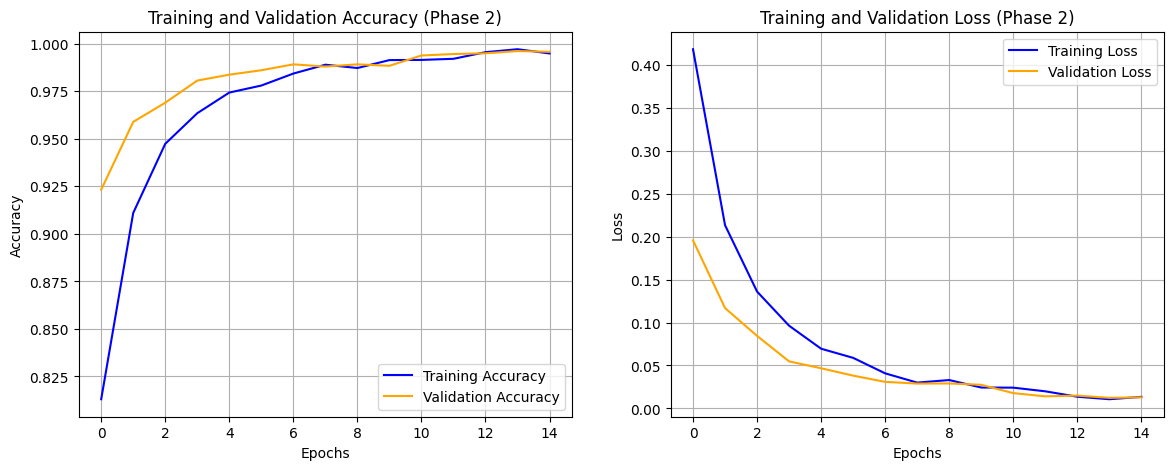

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import EfficientNetB4
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

# --- Configuration & Hyperparameters ---
BATCH_SIZE = 16
IMG_SIZE = (380, 380)
DATA_DIR = "./dataset"

print(f"--- Loading data with resolution {IMG_SIZE} ---")

# Load training and validation datasets
train_dataset = image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

validation_dataset = image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary'
)

# Optimize data loading for performance
train_dataset = train_dataset.prefetch(buffer_size=tf.data.AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=tf.data.AUTOTUNE)


# --- Model Construction & Phase 1 Training ---
base_model = EfficientNetB4(input_shape=(380, 380, 3), include_top=False, weights='imagenet')

# Freeze the base model to retain pre-trained ImageNet features
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
checkpoint_stage1 = ModelCheckpoint('best_deepfake_model_b4_stage1.keras', monitor='val_accuracy', save_best_only=True)

print("--- Starting Phase 1: Training classification head only ---")
history_stage1 = model.fit(
    train_dataset,
    epochs=15,
    validation_data=validation_dataset,
    callbacks=[early_stop, checkpoint_stage1]
)


# --- Phase 2: Fine-Tuning ---
print("--- Starting Phase 2: Fine-tuning ---")

# Unfreeze the base model, but keep the first 100 layers frozen to avoid overfitting
base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False

# Recompile with a very low learning rate to prevent catastrophic forgetting
model.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

checkpoint_stage2 = ModelCheckpoint('/models/EfficientNet_B4_model.keras', monitor='val_accuracy', save_best_only=True)

history_stage2 = model.fit(
    train_dataset,
    epochs=15,
    validation_data=validation_dataset,
    callbacks=[early_stop, checkpoint_stage2]
)

print("--- Full training process completed successfully! ---")


# --- Evaluate and Plot Results ---
acc = history_stage2.history['accuracy']
val_acc = history_stage2.history['val_accuracy']
loss = history_stage2.history['loss']
val_loss = history_stage2.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy', color='blue')
plt.plot(epochs_range, val_acc, label='Validation Accuracy', color='orange')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy (Phase 2)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)

# Plot Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', color='blue')
plt.plot(epochs_range, val_loss, label='Validation Loss', color='orange')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss (Phase 2)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)

plt.show()